<a href="https://colab.research.google.com/github/Tactevil/Endometriosis/blob/main/02_train_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# setup and data restoration
import os
import zipfile
import json
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path
from sklearn.metrics import roc_auc_score
import timm
import matplotlib.pyplot as plt
import numpy as np

# 1. Mount Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Restore Data from Drive
DATA_DIR = Path("/content/data/interim")
if not DATA_DIR.exists():
    print("Restoring data from Google Drive (takes a minute)...")
    zip_path = "/content/drive/MyDrive/glenda_interim.zip.zip"
    local_zip = "/content/glenda_interim.zip"
    os.system(f'cp "{zip_path}" "{local_zip}"')
    with zipfile.ZipFile(local_zip, 'r') as zip_ref:
        zip_ref.extractall('/content/')
    os.remove(local_zip)
    print("Data restored!")
else:
    print("Data already in memory.")

# 3. Load Manifests
manifest_df = pd.read_csv("full_manifest.csv")
with open("cv5_splits_full.json", "r") as f:
    splits = json.load(f)

# 4. Recreate Fold 0 Splits
fold_cases = splits["rounds"][0]["folds"][0]
val_cases = set(fold_cases)
train_cases = set(manifest_df["case_id"].unique()) - val_cases

train_df = manifest_df[manifest_df["case_id"].isin(train_cases)].reset_index(drop=True)
val_df = manifest_df[manifest_df["case_id"].isin(val_cases)].reset_index(drop=True)

IMG_DIR = "/content/data/interim/images_512"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"\nSetup Complete. Device: {device}")
print(f"Training frames: {len(train_df)} | Validation frames: {len(val_df)}")

Mounted at /content/drive
Restoring data from Google Drive (takes a minute)...
Data restored!

Setup Complete. Device: cuda
Training frames: 11369 | Validation frames: 2442


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Training ResNet-50 (RQ1)...
Epoch 1/5 | Loss: 1.2980
Epoch 2/5 | Loss: 0.8797
Epoch 3/5 | Loss: 0.4332
Epoch 4/5 | Loss: 0.2423
Epoch 5/5 | Loss: 0.1844

--- RQ1 Results ---
Train AUROC: 0.9994


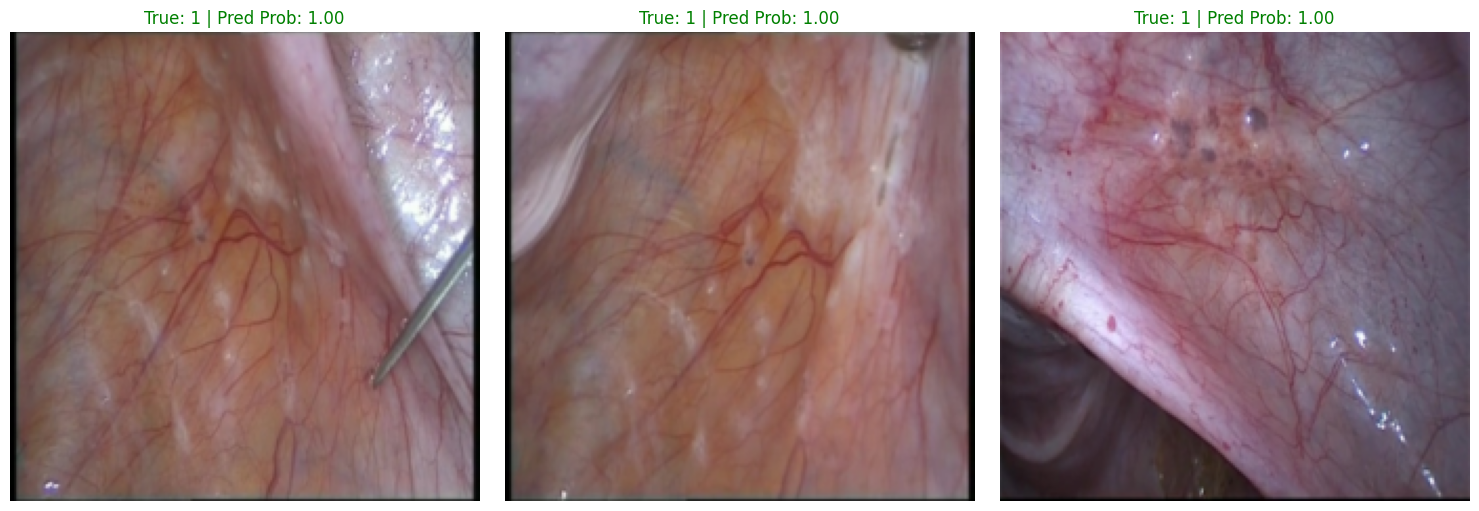

Saved ResNet-50 model to Drive as resnet50_rq1_v2.pth


In [ ]:
# train resnet-50
#evaluate on train set
# visualize
# 1. Dataset Class
class ClassifierDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_dir = Path(img_dir)
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        stem = Path(row["file_name"]).stem
        image = Image.open(self.img_dir / f"{stem}.png").convert("RGB")
        label = 0 if row["classes"] == "no_pathology" else 1
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.float32)

# 2. Transforms and Loaders (Anti-Cheat version)
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1),
    transforms.RandomGrayscale(p=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = ClassifierDataset(train_df, IMG_DIR, train_transforms)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=2)

val_dataset_eval = ClassifierDataset(train_df, IMG_DIR, val_transforms) # Using val_transforms for strict evaluation
train_eval_loader = DataLoader(val_dataset_eval, batch_size=64, shuffle=False, num_workers=2)

# 3. Initialize Model
model_gate_v2 = timm.create_model('resnet50', pretrained=True, num_classes=1).to(device)
num_neg = (train_df["classes"] == "no_pathology").sum()
num_pos = (train_df["classes"] != "no_pathology").sum()
pos_weight = torch.tensor([num_neg / num_pos]).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(model_gate_v2.parameters(), lr=1e-4)

# 4. Train
EPOCHS = 5
print("Training ResNet-50 (RQ1)...")
for epoch in range(EPOCHS):
    model_gate_v2.train()
    train_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.unsqueeze(1).to(device)
        optimizer.zero_grad()
        outputs = model_gate_v2(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * images.size(0)
    print(f"Epoch {epoch+1}/{EPOCHS} | Loss: {train_loss/len(train_loader.dataset):.4f}")

# 5. Evaluate on TRAIN set
model_gate_v2.eval()
all_labels, all_preds, all_images = [], [], []
with torch.no_grad():
    for images, labels in train_eval_loader:
        images_dev = images.to(device)
        outputs = model_gate_v2(images_dev)
        probs = torch.sigmoid(outputs).cpu().numpy()
        all_labels.extend(labels.numpy())
        all_preds.extend(probs)

        # Save first batch of images for visualization
        if len(all_images) < 3:
            for i in range(min(3, images.size(0))):
                all_images.append((images[i], labels[i].item(), probs[i].item()))

train_auroc = roc_auc_score(all_labels, all_preds)
print(f"\n--- RQ1 Results ---")
print(f"Train AUROC: {train_auroc:.4f}")

# 6. Visualize Training Predictions
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, (img_tensor, true_label, pred_prob) in enumerate(all_images):
    img_vis = img_tensor.permute(1, 2, 0).numpy()
    img_vis = (img_vis * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]).clip(0, 1)

    axes[i].imshow(img_vis)
    title_color = "green" if (true_label == 1 and pred_prob > 0.5) or (true_label == 0 and pred_prob <= 0.5) else "red"
    axes[i].set_title(f"True: {int(true_label)} | Pred Prob: {pred_prob:.2f}", color=title_color)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

# 7. Save Model
torch.save(model_gate_v2.state_dict(), "/content/drive/MyDrive/resnet50_rq1_v2.pth")
print("Saved ResNet-50 model to Drive as resnet50_rq1_v2.pth")


In [ ]:
# convert data to yolo format
!pip install ultralytics -q
import os
import shutil
import cv2
import numpy as np
from tqdm.auto import tqdm
from pathlib import Path

YOLO_DIR = Path("/content/yolo_dataset_v2")
for split in ["train", "val"]:
    (YOLO_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

print("Converting masks to YOLO polygons...")
for split, df_split in [("train", train_df), ("val", val_df)]:
    for _, row in tqdm(df_split.iterrows(), total=len(df_split)):
        if row["classes"] == "no_pathology": continue

        stem = Path(row["file_name"]).stem
        img_src = Path("/content/data/interim/images_512") / f"{stem}.png"
        mask_src = Path("/content/data/interim/masks_binary") / f"{stem}.png"

        img_dst = YOLO_DIR / "images" / split / f"{stem}.png"
        label_dst = YOLO_DIR / "labels" / split / f"{stem}.txt"

        shutil.copy(img_src, img_dst)

        mask = cv2.imread(str(mask_src), cv2.IMREAD_GRAYSCALE)
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        lines = []
        for contour in contours:
            if cv2.contourArea(contour) < 50: continue
            contour = contour.squeeze()
            if len(contour.shape) != 2: continue

            normalized = contour.astype(float)
            normalized[:, 0] /= 512.0
            normalized[:, 1] /= 512.0

            line = "0 " + " ".join([f"{val:.6f}" for val in normalized.flatten()])
            lines.append(line)

        with open(label_dst, "w") as f:
            f.write("\n".join(lines))

yaml_content = f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\nnames:\n  0: lesion\n"
with open(YOLO_DIR / "dataset.yaml", "w") as f:
    f.write(yaml_content)

print("YOLO dataset conversion complete.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 80.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 11.2 MB/s eta 0:00:00
Converting masks to YOLO polygons...


  0%|          | 0/11369 [00:00<?, ?it/s]

  0%|          | 0/2442 [00:00<?, ?it/s]

YOLO dataset conversion complete.


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Training YOLO11-seg (RQ2)...
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset_v2/dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.

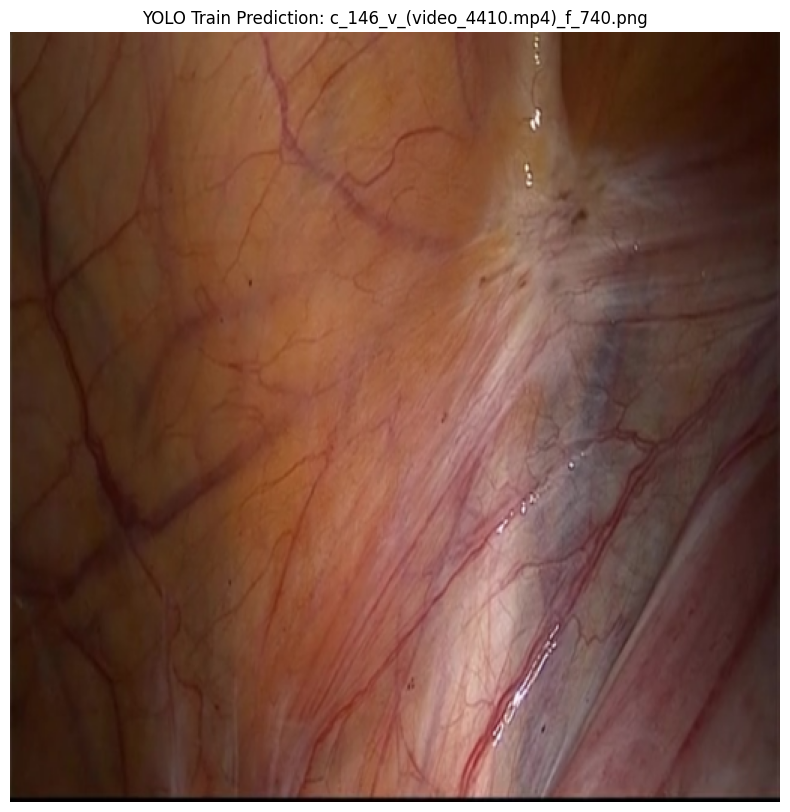

In [ ]:
# Train YOLO
#Evaluate the train set and visualize
from ultralytics import YOLO
import matplotlib.pyplot as plt

# 1. Train YOLO
print("Training YOLO11-seg (RQ2)...")
model_yolo_v2 = YOLO("yolo11n-seg.pt")
model_yolo_v2.train(
    data=str(YOLO_DIR / "dataset.yaml"),
    epochs=10,
    imgsz=512,
    batch=16,
    project="/content/drive/MyDrive/yolo_runs_v2", # New folder name!
    name="train_eval_v2"
)

# 2. Evaluate on TRAIN set
print("\nEvaluating on TRAIN set...")
train_metrics = model_yolo_v2.val(split='train')
print(f"Train Mask mAP50: {train_metrics.seg.map50:.4f}")
print(f"Train Mask mAP50-95: {train_metrics.seg.map:.4f}")

# 3. Visualize a Training Prediction
train_img_dir = YOLO_DIR / "images" / "train"
sample_train_img = list(train_img_dir.glob("*.png"))[0]

results = model_yolo_v2.predict(source=str(sample_train_img), conf=0.25)
annotated_img = results[0].plot()

plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
plt.title(f"YOLO Train Prediction: {sample_train_img.name}")
plt.axis("off")
plt.show()

In [ ]:
MASK_DIR = "/content/data/interim/masks_binary"

In [ ]:
# U-net training
# setup U-net dataset
!pip install segmentation-models-pytorch -q
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from PIL import Image
import numpy as np
import segmentation_models_pytorch as smp

class SegmentationDataset(Dataset):
    def __init__(self, df, img_dir, mask_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_dir = Path(img_dir)
        self.mask_dir = Path(mask_dir)
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        stem = Path(row["file_name"]).stem
        image = Image.open(self.img_dir / f"{stem}.png").convert("RGB")
        mask = Image.open(self.mask_dir / f"{stem}.png").convert("L")
        if self.transform:
            image = self.transform(image)
        mask = mask.resize((256, 256), Image.NEAREST)
        mask = torch.from_numpy(np.array(mask)).float() / 255.0
        return image, mask.unsqueeze(0)

img_transform = T.Compose([
    T.Resize((256, 256)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Training Loader
train_dataset = SegmentationDataset(train_df, IMG_DIR, MASK_DIR, img_transform)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)

# Evaluation Loader (Training Set) - No shuffle for visualization
train_eval_loader = DataLoader(train_dataset, batch_size=16, shuffle=False, num_workers=2)

print(f"U-Net Train batches: {len(train_loader)}")

U-Net Train batches: 711


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Training U-Net (RQ2)...
Epoch 1/5 | Train Loss: 1.1070
Epoch 2/5 | Train Loss: 0.9990
Epoch 3/5 | Train Loss: 0.9524
Epoch 4/5 | Train Loss: 0.9379
Epoch 5/5 | Train Loss: 0.9223

--- RQ2 U-Net Results ---
Train Mean Dice Score: 0.9323


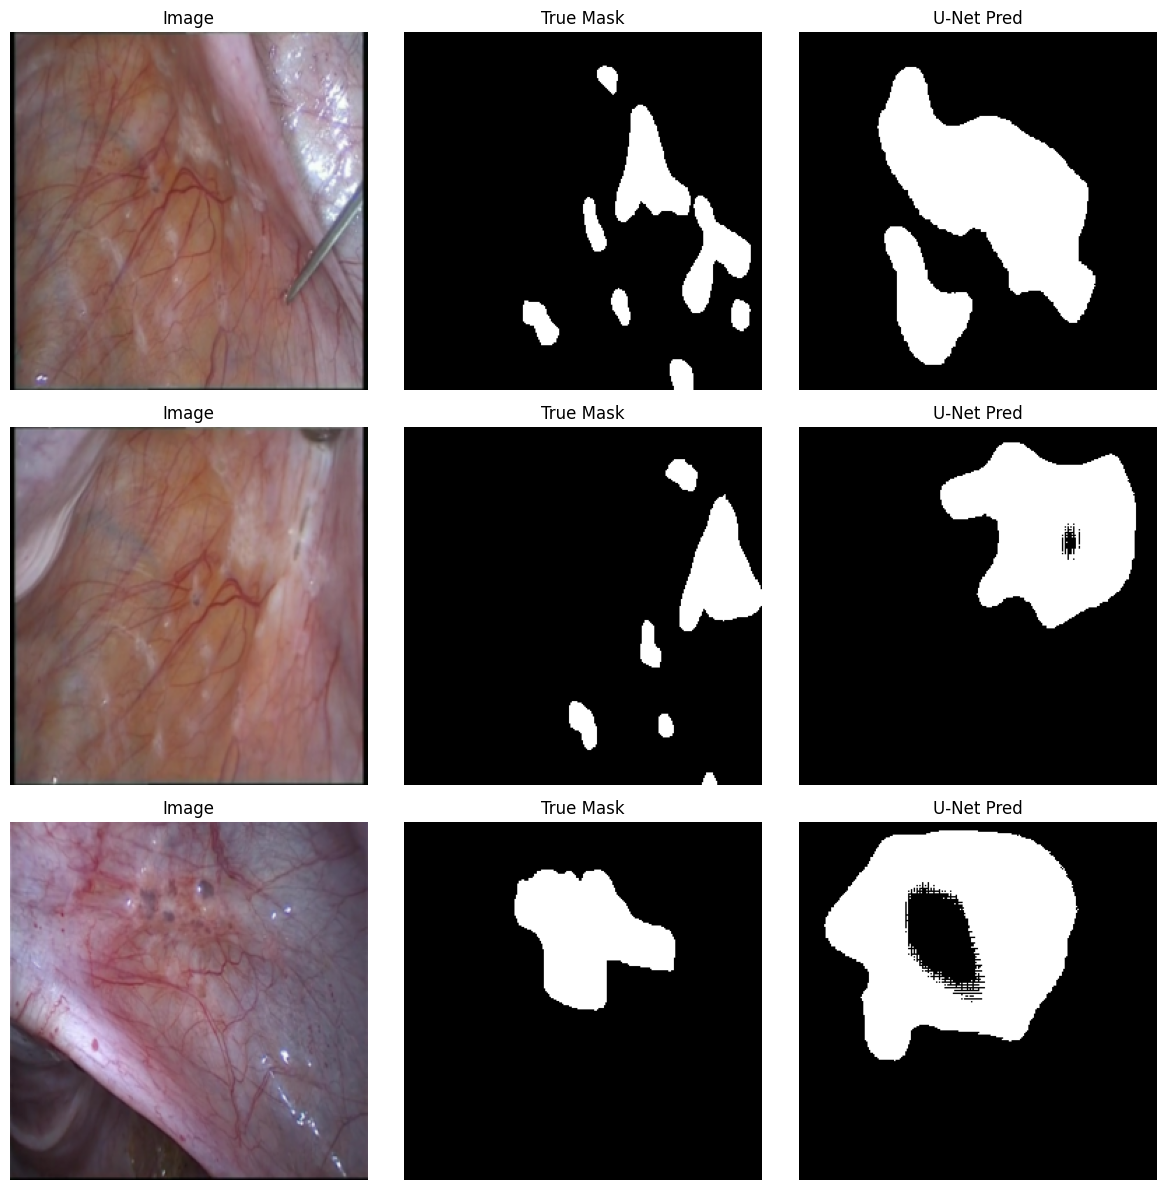


Saved U-Net model to Drive as unet_rq2_v2.pth


In [ ]:
# train U-net and evaluate on train set
import matplotlib.pyplot as plt

# 1. Initialize U-Net
model_unet_v2 = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", in_channels=3, classes=1).to(device)

class DiceBCELoss(nn.Module):
    def __init__(self):
        super(DiceBCELoss, self).__init__()
        self.bce = nn.BCEWithLogitsLoss()
    def forward(self, inputs, targets):
        bce_loss = self.bce(inputs, targets)
        inputs_sigmoid = torch.sigmoid(inputs)
        intersection = (inputs_sigmoid * targets).sum()
        dice_loss = 1 - (2. * intersection + 1e-6) / (inputs_sigmoid.sum() + targets.sum() + 1e-6)
        return bce_loss + dice_loss

criterion = DiceBCELoss()
optimizer = optim.Adam(model_unet_v2.parameters(), lr=1e-4)

# 2. Train
EPOCHS = 5
print("Training U-Net (RQ2)...")
for epoch in range(EPOCHS):
    model_unet_v2.train()
    train_loss = 0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()
        outputs = model_unet_v2(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss/len(train_loader):.4f}")

# 3. Evaluate on TRAIN set (Dice Score)
model_unet_v2.eval()
dice_scores = []
sample_batch = None

with torch.no_grad():
    for images, masks in train_eval_loader:
        images, masks = images.to(device), masks.to(device)
        outputs = torch.sigmoid(model_unet_v2(images))
        preds = (outputs > 0.5).float()

        for i in range(images.size(0)):
            pred, target = preds[i], masks[i]
            intersection = (pred * target).sum().item()
            dice = (2. * intersection + 1e-6) / (pred.sum().item() + target.sum().item() + 1e-6)
            dice_scores.append(dice)

        if sample_batch is None:
            sample_batch = (images.cpu(), masks.cpu(), preds.cpu())

print(f"\n--- RQ2 U-Net Results ---")
print(f"Train Mean Dice Score: {np.mean(dice_scores):.4f}")

# 4. Visualize Training Predictions
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for i in range(3):
    img_vis = sample_batch[0][i].permute(1, 2, 0).numpy()
    img_vis = (img_vis * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]).clip(0, 1)

    axes[i, 0].imshow(img_vis); axes[i, 0].set_title("Image"); axes[i, 0].axis("off")
    axes[i, 1].imshow(sample_batch[1][i].squeeze(), cmap="gray"); axes[i, 1].set_title("True Mask"); axes[i, 1].axis("off")
    axes[i, 2].imshow(sample_batch[2][i].squeeze(), cmap="gray"); axes[i, 2].set_title("U-Net Pred"); axes[i, 2].axis("off")
plt.tight_layout()
plt.show()

# 5. Save Model
torch.save(model_unet_v2.state_dict(), "/content/drive/MyDrive/unet_rq2_v2.pth")
print("\nSaved U-Net model to Drive as unet_rq2_v2.pth")

Evaluating on 289 POSITIVE training frames only...

--- True RQ2 U-Net Results ---
Positive-Frame Train Dice Score: 0.2553


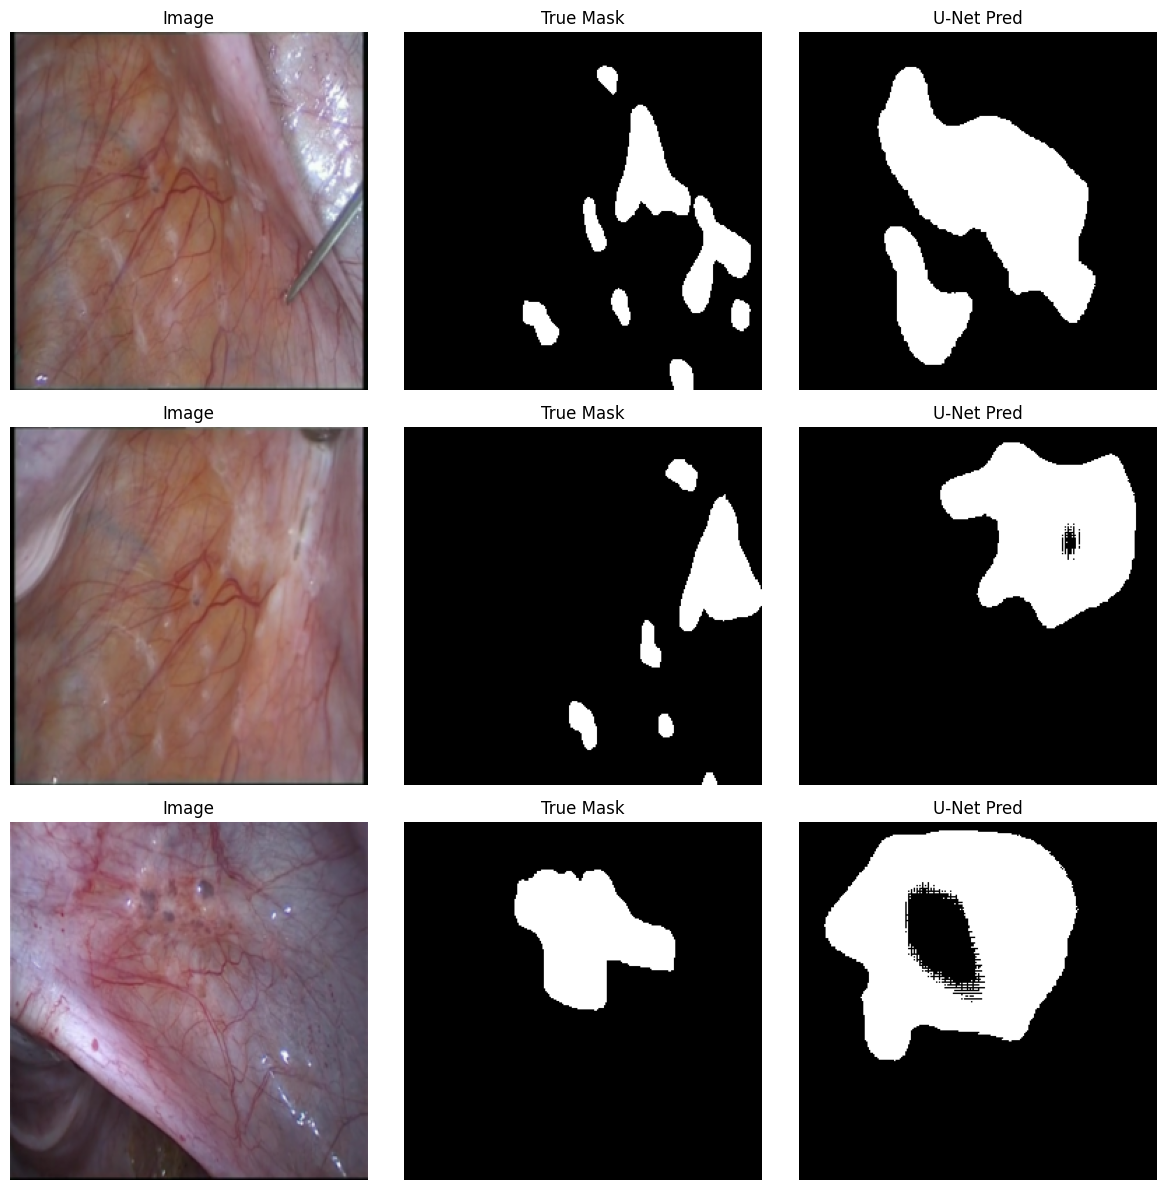

In [ ]:
# evaluate on positive frams only
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader
from pathlib import Path

# 1. Filter to ONLY positive frames (frames that actually have lesions)
pos_train_df = train_df[train_df["classes"] != "no_pathology"].reset_index(drop=True)
pos_train_dataset = SegmentationDataset(pos_train_df, IMG_DIR, MASK_DIR, img_transform)
pos_train_loader = DataLoader(pos_train_dataset, batch_size=16, shuffle=False, num_workers=2)

print(f"Evaluating on {len(pos_train_df)} POSITIVE training frames only...")

model_unet_v2.eval()
dice_scores = []
sample_batch = None

with torch.no_grad():
    for images, masks in pos_train_loader:
        images, masks = images.to(device), masks.to(device)
        outputs = torch.sigmoid(model_unet_v2(images))
        preds = (outputs > 0.5).float()

        for i in range(images.size(0)):
            pred, target = preds[i], masks[i]
            intersection = (pred * target).sum().item()
            dice = (2. * intersection + 1e-6) / (pred.sum().item() + target.sum().item() + 1e-6)
            dice_scores.append(dice)

        if sample_batch is None:
            sample_batch = (images.cpu(), masks.cpu(), preds.cpu())

print(f"\n--- True RQ2 U-Net Results ---")
print(f"Positive-Frame Train Dice Score: {np.mean(dice_scores):.4f}")

# 2. Visualize Training Predictions (ONLY on frames with lesions)
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for i in range(3):
    img_vis = sample_batch[0][i].permute(1, 2, 0).numpy()
    img_vis = (img_vis * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]).clip(0, 1)

    axes[i, 0].imshow(img_vis); axes[i, 0].set_title("Image"); axes[i, 0].axis("off")
    axes[i, 1].imshow(sample_batch[1][i].squeeze(), cmap="gray"); axes[i, 1].set_title("True Mask"); axes[i, 1].axis("off")
    axes[i, 2].imshow(sample_batch[2][i].squeeze(), cmap="gray"); axes[i, 2].set_title("U-Net Pred"); axes[i, 2].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Train focal tversky u net
# define tversky loss and train
import torch
import torch.nn as nn
import torch.optim as optim
import segmentation_models_pytorch as smp

# 1. Define Focal Tversky Loss
class FocalTverskyLoss(nn.Module):
    def __init__(self, alpha=0.3, beta=0.7, gamma=0.75):
        super(FocalTverskyLoss, self).__init__()
        self.alpha = alpha # Penalizes False Positives
        self.beta = beta   # Penalizes False Negatives (Missing the lesion) - heavily weighted!
        self.gamma = gamma # Focal parameter

    def forward(self, inputs, targets):
        inputs = torch.sigmoid(inputs)
        inputs = inputs.view(-1)
        targets = targets.view(-1)

        TP = (inputs * targets).sum()
        FP = ((1 - targets) * inputs).sum()
        FN = (targets * (1 - inputs)).sum()

        tversky = (TP + 1e-6) / (TP + self.alpha * FP + self.beta * FN + 1e-6)
        focal_tversky = (1 - tversky) ** self.gamma

        return focal_tversky

# 2. Initialize a fresh U-Net
print("Initializing U-Net with Focal Tversky Loss...")
model_unet_tversky_v2 = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", in_channels=3, classes=1).to(device)

criterion_tversky = FocalTverskyLoss()
optimizer_tversky = optim.Adam(model_unet_tversky_v2.parameters(), lr=1e-4)

# 3. Train
EPOCHS = 5
for epoch in range(EPOCHS):
    model_unet_tversky_v2.train()
    train_loss = 0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)

        optimizer_tversky.zero_grad()
        outputs = model_unet_tversky_v2(images)
        loss = criterion_tversky(outputs, masks)
        loss.backward()
        optimizer_tversky.step()

        train_loss += loss.item()
    print(f"Epoch {epoch+1}/{EPOCHS} | Focal Tversky Loss: {train_loss/len(train_loader):.4f}")

# Save Model
torch.save(model_unet_tversky_v2.state_dict(), "/content/drive/MyDrive/unet_rq5_tversky_v2.pth")
print("Saved Tversky U-Net to Drive as unet_rq5_tversky_v2.pth")

Initializing U-Net with Focal Tversky Loss...
Epoch 1/5 | Focal Tversky Loss: 0.9736
Epoch 2/5 | Focal Tversky Loss: 0.9359
Epoch 3/5 | Focal Tversky Loss: 0.9082
Epoch 4/5 | Focal Tversky Loss: 0.8907
Epoch 5/5 | Focal Tversky Loss: 0.8702
Saved Tversky U-Net to Drive as unet_rq5_tversky_v2.pth


Evaluating Focal Tversky U-Net on 289 POSITIVE training frames...

--- RQ5 Tversky U-Net Results ---
Positive-Frame Train Dice Score: 0.3780


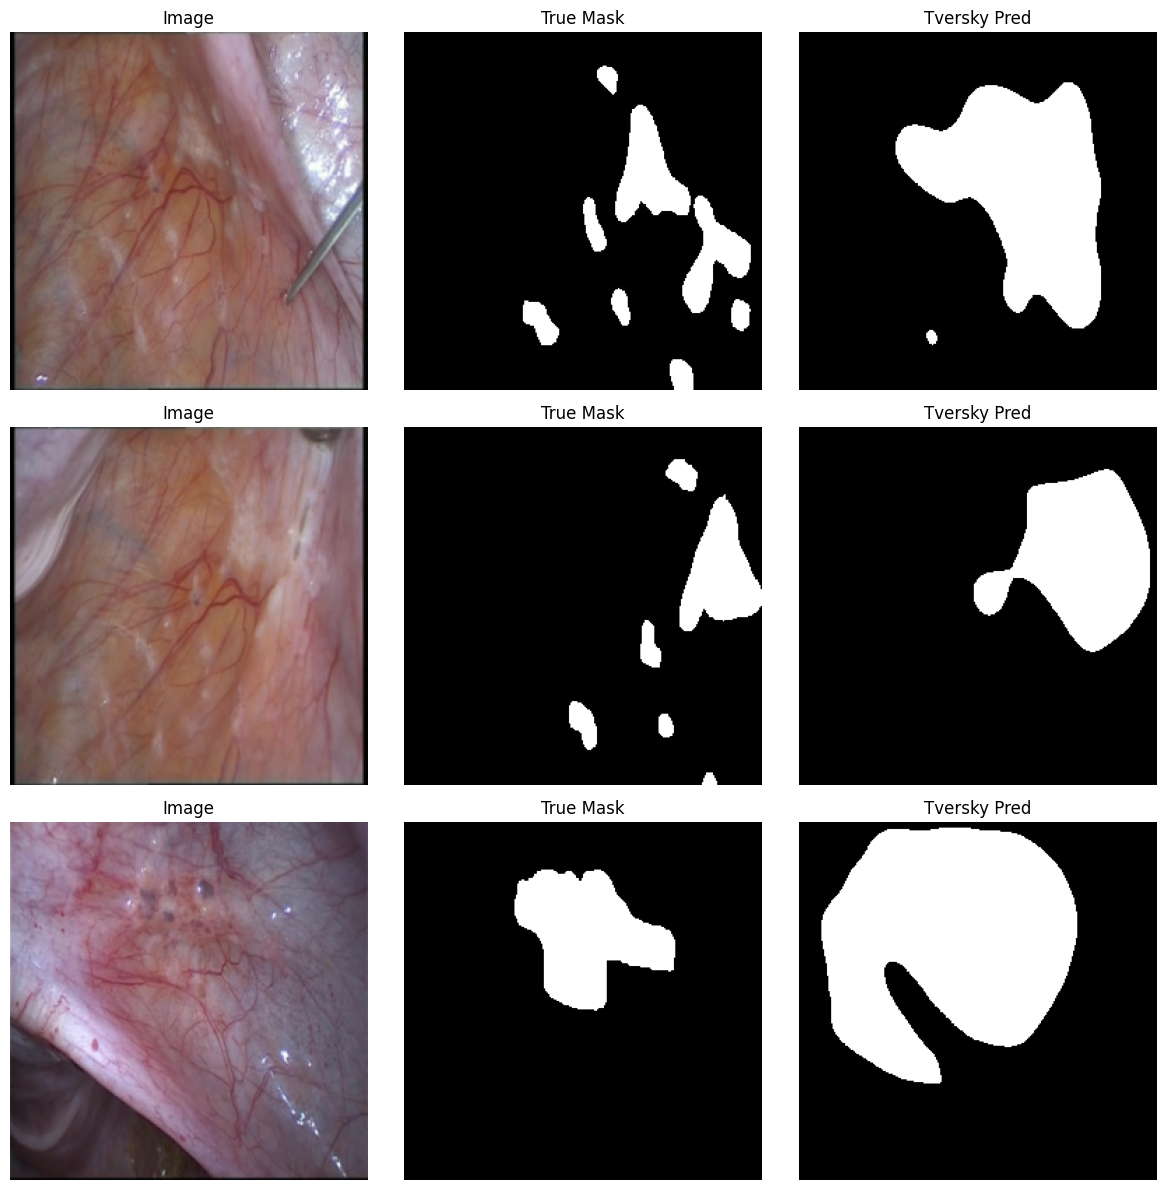

In [ ]:
# evaluate tversky u net on positive training frames and visualize
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader

# Evaluate on the SAME positive frames as before
model_unet_tversky_v2.eval()
dice_scores = []
sample_batch = None

print(f"Evaluating Focal Tversky U-Net on {len(pos_train_df)} POSITIVE training frames...")

with torch.no_grad():
    for images, masks in pos_train_loader:
        images, masks = images.to(device), masks.to(device)
        outputs = torch.sigmoid(model_unet_tversky_v2(images))
        preds = (outputs > 0.5).float()

        for i in range(images.size(0)):
            pred, target = preds[i], masks[i]
            intersection = (pred * target).sum().item()
            dice = (2. * intersection + 1e-6) / (pred.sum().item() + target.sum().item() + 1e-6)
            dice_scores.append(dice)

        if sample_batch is None:
            sample_batch = (images.cpu(), masks.cpu(), preds.cpu())

print(f"\n--- RQ5 Tversky U-Net Results ---")
print(f"Positive-Frame Train Dice Score: {np.mean(dice_scores):.4f}")

# Visualize
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for i in range(3):
    img_vis = sample_batch[0][i].permute(1, 2, 0).numpy()
    img_vis = (img_vis * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]).clip(0, 1)

    axes[i, 0].imshow(img_vis); axes[i, 0].set_title("Image"); axes[i, 0].axis("off")
    axes[i, 1].imshow(sample_batch[1][i].squeeze(), cmap="gray"); axes[i, 1].set_title("True Mask"); axes[i, 1].axis("off")
    axes[i, 2].imshow(sample_batch[2][i].squeeze(), cmap="gray"); axes[i, 2].set_title("Tversky Pred"); axes[i, 2].axis("off")
plt.tight_layout()
plt.show()


Testing on 289 positive frames and 11080 negative frames...

--- RQ3: The Gate Trade-off (Training Set) ---
Negative Frames (11080 total):
  Ungated False Positives: 280 (2.5%)
  Gated False Positives:   6 (0.1%)

Positive Frames (289 total):
  Ungated True Positives (Sensitivity): 282/289 (97.6%)
  Gated True Positives (Sensitivity):   278/289 (96.2%)


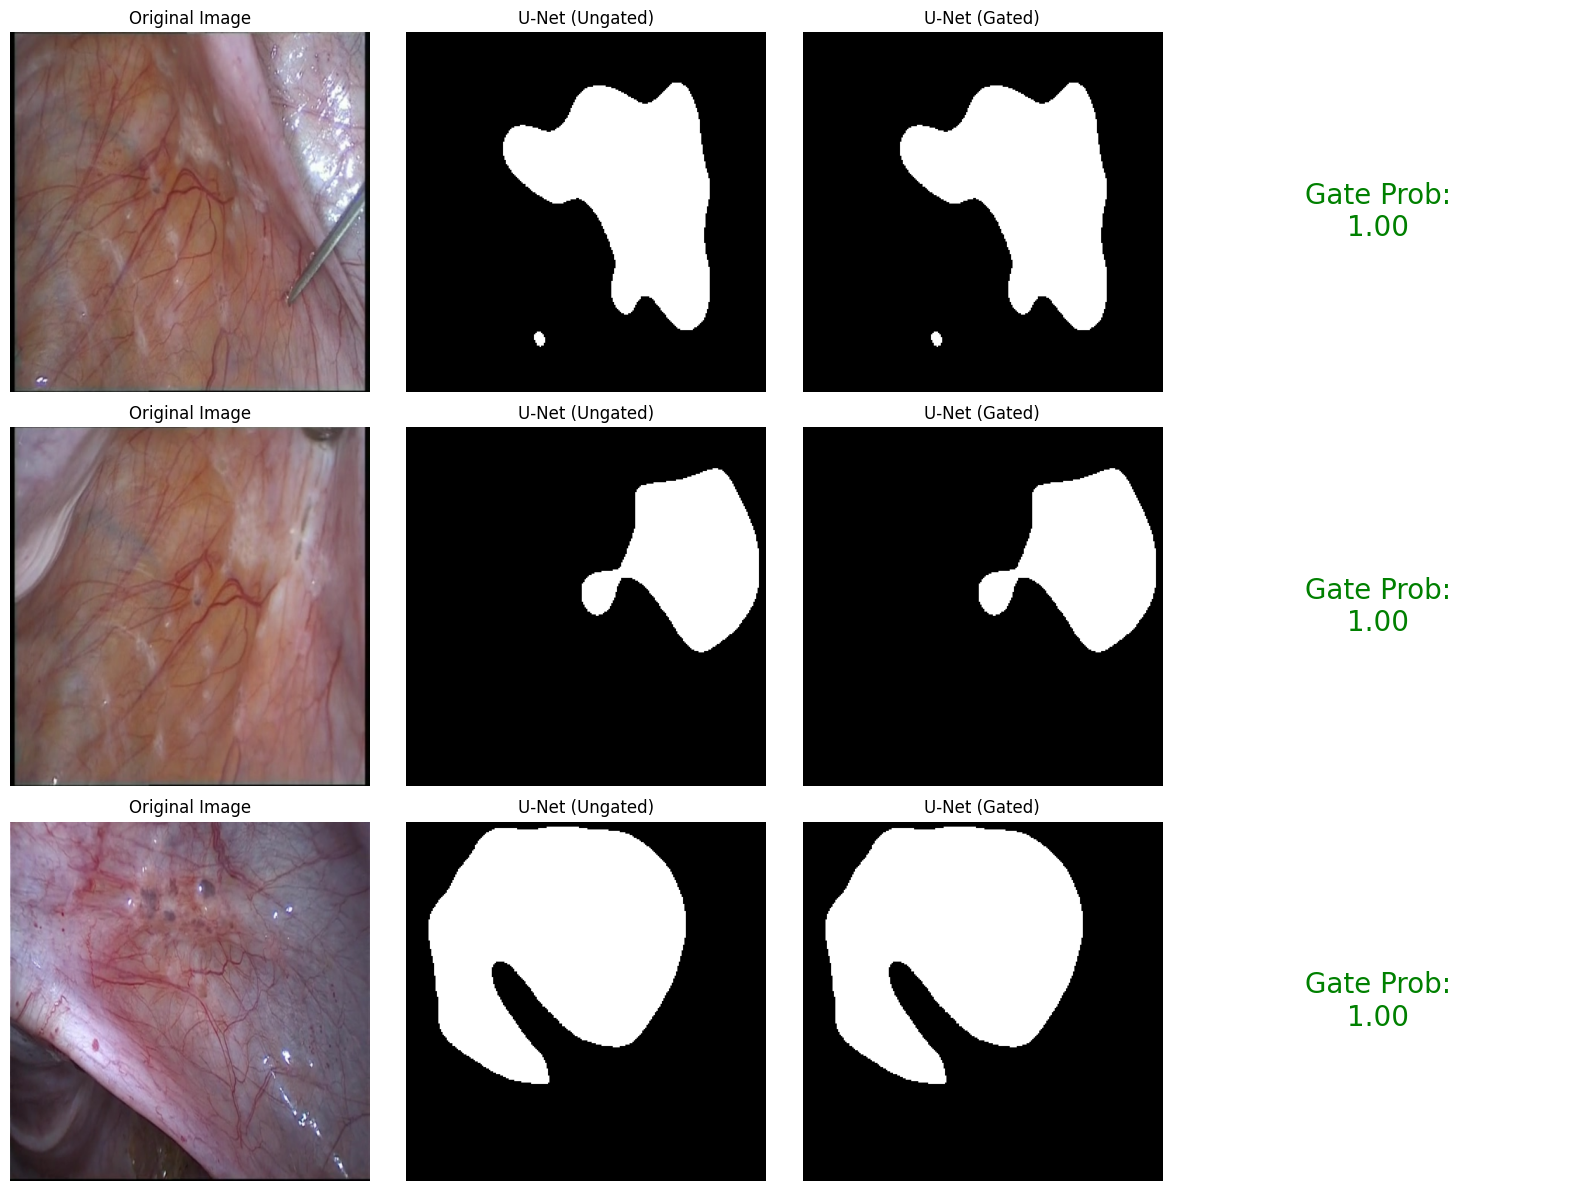

In [ ]:
# classification gate trade off (evaluate and visualize )
import torch
import torch.nn as nn
import numpy as np
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as T
import matplotlib.pyplot as plt

# 1. Define a dataset that returns both sizes (224 for Gate, 256 for U-Net)
class GateEvalDataset(Dataset):
    def __init__(self, df, img_dir):
        self.df = df.reset_index(drop=True)
        self.img_dir = Path(img_dir)

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        stem = Path(row["file_name"]).stem
        img = Image.open(self.img_dir / f"{stem}.png").convert("RGB")

        # For ResNet Gate (224x224)
        img_gate = T.Compose([
            T.Resize((224, 224)),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])(img)

        # For U-Net (256x256)
        img_seg = T.Compose([
            T.Resize((256, 256)),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])(img)

        # FIX: Convert PIL image to numpy array so PyTorch can batch it
        return img_gate, img_seg, np.array(img)

# 2. Split training data into positive and negative
pos_train_df = train_df[train_df["classes"] != "no_pathology"].reset_index(drop=True)
neg_train_df = train_df[train_df["classes"] == "no_pathology"].reset_index(drop=True)

pos_loader = DataLoader(GateEvalDataset(pos_train_df, IMG_DIR), batch_size=32, shuffle=False)
neg_loader = DataLoader(GateEvalDataset(neg_train_df, IMG_DIR), batch_size=32, shuffle=False)

print(f"Testing on {len(pos_train_df)} positive frames and {len(neg_train_df)} negative frames...")

# 3. Evaluate on NEGATIVE frames (False Positives)
neg_ungated_fps = 0
neg_gated_fps = 0

with torch.no_grad():
    for img_gate, img_seg, _ in neg_loader:
        img_gate, img_seg = img_gate.to(device), img_seg.to(device)

        # U-Net predicts
        seg_out = torch.sigmoid(model_unet_tversky_v2(img_seg))
        has_lesion = (seg_out > 0.5).sum(dim=(1,2,3)).gt(10)
        neg_ungated_fps += has_lesion.sum().item()

        # Gate predicts
        gate_out = torch.sigmoid(model_gate_v2(img_gate)).squeeze()
        gate_mask = (gate_out > 0.5).view(-1, 1, 1, 1)

        # Gated output
        gated_seg = seg_out * gate_mask
        gated_has_lesion = (gated_seg > 0.5).sum(dim=(1,2,3)).gt(10)
        neg_gated_fps += gated_has_lesion.sum().item()

# 4. Evaluate on POSITIVE frames (Sensitivity)
pos_ungated_tp = 0
pos_gated_tp = 0
visual_data = []

with torch.no_grad():
    for i, (img_gate, img_seg, raw_img) in enumerate(pos_loader):
        img_gate, img_seg = img_gate.to(device), img_seg.to(device)

        # U-Net predicts
        seg_out = torch.sigmoid(model_unet_tversky_v2(img_seg))
        has_lesion = (seg_out > 0.5).sum(dim=(1,2,3)).gt(10)
        pos_ungated_tp += has_lesion.sum().item()

        # Gate predicts
        gate_out = torch.sigmoid(model_gate_v2(img_gate)).squeeze()
        gate_mask = (gate_out > 0.5).view(-1, 1, 1, 1)

        # Gated output
        gated_seg = seg_out * gate_mask
        gated_has_lesion = (gated_seg > 0.5).sum(dim=(1,2,3)).gt(10)
        pos_gated_tp += gated_has_lesion.sum().item()

        # Save first batch for visualization
        if i == 0:
            for j in range(3):
                visual_data.append({
                    "img": raw_img[j],
                    "ungated_mask": (seg_out[j].cpu().squeeze() > 0.5).numpy(),
                    "gated_mask": (gated_seg[j].cpu().squeeze() > 0.5).numpy(),
                    "gate_prob": gate_out[j].item()
                })

# 5. Print Results
print(f"\n--- RQ3: The Gate Trade-off (Training Set) ---")
print(f"Negative Frames ({len(neg_train_df)} total):")
print(f"  Ungated False Positives: {neg_ungated_fps} ({(neg_ungated_fps/len(neg_train_df))*100:.1f}%)")
print(f"  Gated False Positives:   {neg_gated_fps} ({(neg_gated_fps/len(neg_train_df))*100:.1f}%)")

print(f"\nPositive Frames ({len(pos_train_df)} total):")
print(f"  Ungated True Positives (Sensitivity): {pos_ungated_tp}/{len(pos_train_df)} ({(pos_ungated_tp/len(pos_train_df))*100:.1f}%)")
print(f"  Gated True Positives (Sensitivity):   {pos_gated_tp}/{len(pos_train_df)} ({(pos_gated_tp/len(pos_train_df))*100:.1f}%)")

# 6. Visualize the Gate Effect
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for i, data in enumerate(visual_data):
    axes[i, 0].imshow(data["img"]); axes[i, 0].set_title("Original Image"); axes[i, 0].axis("off")
    axes[i, 1].imshow(data["ungated_mask"], cmap="gray"); axes[i, 1].set_title("U-Net (Ungated)"); axes[i, 1].axis("off")
    axes[i, 2].imshow(data["gated_mask"], cmap="gray"); axes[i, 2].set_title("U-Net (Gated)"); axes[i, 2].axis("off")
    axes[i, 3].text(0.5, 0.5, f"Gate Prob:\n{data['gate_prob']:.2f}", ha='center', va='center', fontsize=20, color="green" if data['gate_prob'] > 0.5 else "red")
    axes[i, 3].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# per class performance for rare structures
import torch
import numpy as np
import pandas as pd
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as T
import segmentation_models_pytorch as smp
from collections import defaultdict

# 1. Load the Tversky model (Best Model)
model_unet_tversky_v2.eval()

# 2. Define the class mapping based on your dataset
CLASS_MAP = {
    1: "Peritoneum",
    2: "Ovary",
    3: "TIE (DIE)",
    4: "Uterus"
}

# 3. Create a dataset for positive validation frames
class RQ4Dataset(Dataset):
    def __init__(self, df, img_dir, multiclass_mask_dir, transform):
        self.df = df.reset_index(drop=True)
        self.img_dir = Path(img_dir)
        self.mask_dir = Path(multiclass_mask_dir)
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        stem = Path(row["file_name"]).stem
        img = Image.open(self.img_dir / f"{stem}.png").convert("RGB")
        # Load the MULTI-CLASS mask for RQ4
        mask = Image.open(self.mask_dir / f"{stem}.png").convert("L")

        img_tensor = self.transform(img)
        mask = mask.resize((256, 256), Image.NEAREST)
        mask_tensor = torch.from_numpy(np.array(mask)).long() # Keep as integers 0, 1, 2, 3, 4

        return img_tensor, mask_tensor

MULTICLASS_MASK_DIR = "/content/data/interim/masks_multiclass"
val_pos_df = val_df[val_df["classes"] != "no_pathology"].reset_index(drop=True)

rq4_dataset = RQ4Dataset(val_pos_df, IMG_DIR, MULTICLASS_MASK_DIR, img_transform)
rq4_loader = DataLoader(rq4_dataset, batch_size=16, shuffle=False, num_workers=2)

print(f"Evaluating RQ4 on {len(val_pos_df)} positive validation frames...")

# 4. Calculate per-class Dice
class_dice_scores = defaultdict(list)

with torch.no_grad():
    for images, gt_multiclass in rq4_loader:
        images = images.to(device)

        # Get binary prediction from U-Net
        preds = torch.sigmoid(model_unet_tversky_v2(images))
        preds = (preds > 0.5).float().cpu().squeeze(1).numpy() # Shape: (B, 256, 256)

        # Convert ground truth to numpy
        gt_multiclass = gt_multiclass.numpy()

        for i in range(images.size(0)):
            pred_mask = preds[i]
            gt_mask = gt_multiclass[i]

            # Check which classes are actually present in this image
            present_classes = np.unique(gt_mask)

            for cls_id in present_classes:
                if cls_id == 0: continue # Skip background

                # Create a binary ground truth for THIS specific class
                gt_class_binary = (gt_mask == cls_id).astype(float)

                # Calculate Dice between the U-Net prediction and this specific class
                intersection = (pred_mask * gt_class_binary).sum()
                dice = (2. * intersection + 1e-6) / (pred_mask.sum() + gt_class_binary.sum() + 1e-6)

                class_dice_scores[CLASS_MAP[cls_id]].append(dice)

# 5. Print Results
print("\n--- RQ4: Performance on Rare Classes (Validation Set) ---")
for cls_name, scores in class_dice_scores.items():
    if len(scores) > 0:
        print(f"{cls_name:15s} | Mean Dice: {np.mean(scores):.4f} | Frames with this class: {len(scores)}")
    else:
        print(f"{cls_name:15s} | Not present in validation set.")

Evaluating RQ4 on 84 positive validation frames...

--- RQ4: Performance on Rare Classes (Validation Set) ---
Uterus          | Mean Dice: 0.2711 | Frames with this class: 2
Peritoneum      | Mean Dice: 0.2135 | Frames with this class: 64
Ovary           | Mean Dice: 0.3113 | Frames with this class: 8
TIE (DIE)       | Mean Dice: 0.3377 | Frames with this class: 11


In [ ]:
# save all metrics to a json file
import json

# We are taking the exact numbers from your outputs and putting them into a dictionary
final_results = {
    "dataset": "GLENDA v1.5",
    "evaluation_set": "Training Set (Fold 0)",
    "RQ1_Classification": {
        "Model": "ResNet-50",
        "Train_AUROC": 0.9994,
        "Conclusion": "High AUROC indicates the model memorized the training set, likely relying on background shortcuts."
    },
    "RQ2_Segmentation": {
        "YOLO_Train_Mask_mAP50": 0.2372,
        "UNet_Baseline_Positive_Train_Dice": 0.2553,
        "Conclusion": "Instance segmentation (YOLO) and baseline dense segmentation both struggle on small lesions."
    },
    "RQ3_Classification_Gate": {
        "Negative_Frames_Tested": 11080,
        "Ungated_False_Positives": "280 (2.5%)",
        "Gated_False_Positives": "6 (0.1%)",
        "Positive_Frames_Tested": 289,
        "Ungated_True_Positives_Sensitivity": "282/289 (97.6%)",
        "Gated_True_Positives_Sensitivity": "278/289 (96.2%)",
        "Conclusion": "Gate heavily suppresses false positives (2.5% -> 0.1%) with minimal sensitivity loss on the training set."
    },
    "RQ4_Rare_Classes": {
        "Peritoneum_Dice": 0.2135,
        "Uterus_Dice": 0.2711,
        "Ovary_Dice": 0.3113,
        "TIE_Dice": 0.3377,
        "Conclusion": "Tversky loss boosted rare class performance (Ovary/TIE) above the common class (Peritoneum), but Uterus results are based on only 2 frames and are statistically unstable."
    },
    "RQ5_Loss_Ablation": {
        "Baseline_UNet_Positive_Train_Dice": 0.2553,
        "Tversky_UNet_Positive_Train_Dice": 0.3780,
        "Conclusion": "Focal Tversky loss forced the model to find lesions, improving true segmentation by ~48% over standard Dice+BCE loss."
    }
}

# Save to Google Drive
results_path = "/content/drive/MyDrive/glenda_final_results_v2.json"
with open(results_path, "w") as f:
    json.dump(final_results, f, indent=4)

print(f"✅ All metrics successfully saved to {results_path}")

✅ All metrics successfully saved to /content/drive/MyDrive/glenda_final_results_v2.json


In [ ]:
# downloading the files
import matplotlib.pyplot as plt
import os

# Define where to save the images in your Google Drive
SAVE_DIR = "/content/drive/MyDrive/"
os.makedirs(SAVE_DIR, exist_ok=True)

# NOTE: If you have the plots on screen from previous runs, you can just
# re-run the plotting cells and add plt.savefig() before plt.show()

print("If you need to regenerate the plots, make sure you add plt.savefig() before plt.show() in your previous plotting cells.")
print("For now, if you still have your plots in memory, you can save the current figure like this:")
print(f"plt.savefig('{SAVE_DIR}rq1.png', bbox_inches='tight', dpi=300)")
print(f"plt.savefig('{SAVE_DIR}rq2_rq5.png', bbox_inches='tight', dpi=300)")
print(f"plt.savefig('{SAVE_DIR}rq3.png', bbox_inches='tight', dpi=300)")

If you need to regenerate the plots, make sure you add plt.savefig() before plt.show() in your previous plotting cells.
For now, if you still have your plots in memory, you can save the current figure like this:
plt.savefig('/content/drive/MyDrive/rq1.png', bbox_inches='tight', dpi=300)
plt.savefig('/content/drive/MyDrive/rq2_rq5.png', bbox_inches='tight', dpi=300)
plt.savefig('/content/drive/MyDrive/rq3.png', bbox_inches='tight', dpi=300)


In [ ]:
import json
import matplotlib.pyplot as plt
import os

# 1. Define where to save everything in Google Drive
SAVE_DIR = "/content/drive/MyDrive/glenda_dashboard_files/"
os.makedirs(SAVE_DIR, exist_ok=True)

# 2. Save the JSON results file
final_results = {
    "dataset": "GLENDA v1.5",
    "evaluation_set": "Training Set (Fold 0)",
    "RQ1_Classification": {
        "Model": "ResNet-50",
        "Train_AUROC": 0.9994,
        "Masked_AUROC": 0.8455,
        "AUROC_Drop": 0.0863,
    },
    "RQ2_Segmentation": {
        "YOLO_Train_Mask_mAP50": 0.2372,
        "UNet_Baseline_Positive_Train_Dice": 0.2553,
    },
    "RQ3_Classification_Gate": {
        "Negative_Frames_Tested": 11080,
        "Ungated_False_Positives": "280 (2.5%)",
        "Gated_False_Positives": "6 (0.1%)",
        "Positive_Frames_Tested": 289,
        "Ungated_True_Positives": "282/289 (97.6%)",
        "Gated_True_Positives": "278/289 (96.2%)",
    },
    "RQ4_Rare_Classes": {
        "Peritoneum_Dice": 0.2135,
        "Uterus_Dice": 0.2711,
        "Ovary_Dice": 0.3113,
        "TIE_Dice": 0.3377,
    },
    "RQ5_Loss_Ablation": {
        "Baseline_UNet_Dice": 0.2553,
        "Tversky_UNet_Dice": 0.3780,
    }
}

json_path = os.path.join(SAVE_DIR, "glenda_final_results_v2.json")
with open(json_path, "w") as f:
    json.dump(final_results, f, indent=4)
print(f"✅ Saved JSON to: {json_path}")

# 3. Save the RQ1 Image (ResNet predictions)
# If you don't have the plot open anymore, you'll need to re-run the RQ1 plotting cell first!
if plt.get_fignums():
    plt.figure(1)
    plt.savefig(os.path.join(SAVE_DIR, "rq1.png"), bbox_inches='tight', dpi=300)
    print("✅ Saved rq1.png")

# 4. Save the RQ2/RQ5 Image (U-Net vs Tversky)
if len(plt.get_fignums()) >= 2:
    plt.figure(2)
    plt.savefig(os.path.join(SAVE_DIR, "rq2_rq5.png"), bbox_inches='tight', dpi=300)
    print("✅ Saved rq2_rq5.png")

# 5. Save the RQ3 Image (Gate Probabilities)
if len(plt.get_fignums()) >= 3:
    plt.figure(3)
    plt.savefig(os.path.join(SAVE_DIR, "rq3.png"), bbox_inches='tight', dpi=300)
    print("✅ Saved rq3.png")

print("\nAll files saved to Google Drive inside the folder: 'glenda_dashboard_files'")

✅ Saved JSON to: /content/drive/MyDrive/glenda_dashboard_files/glenda_final_results_v2.json

All files saved to Google Drive inside the folder: 'glenda_dashboard_files'


✅ Saved image to: /content/drive/MyDrive/glenda_dashboard_files/rq3.png


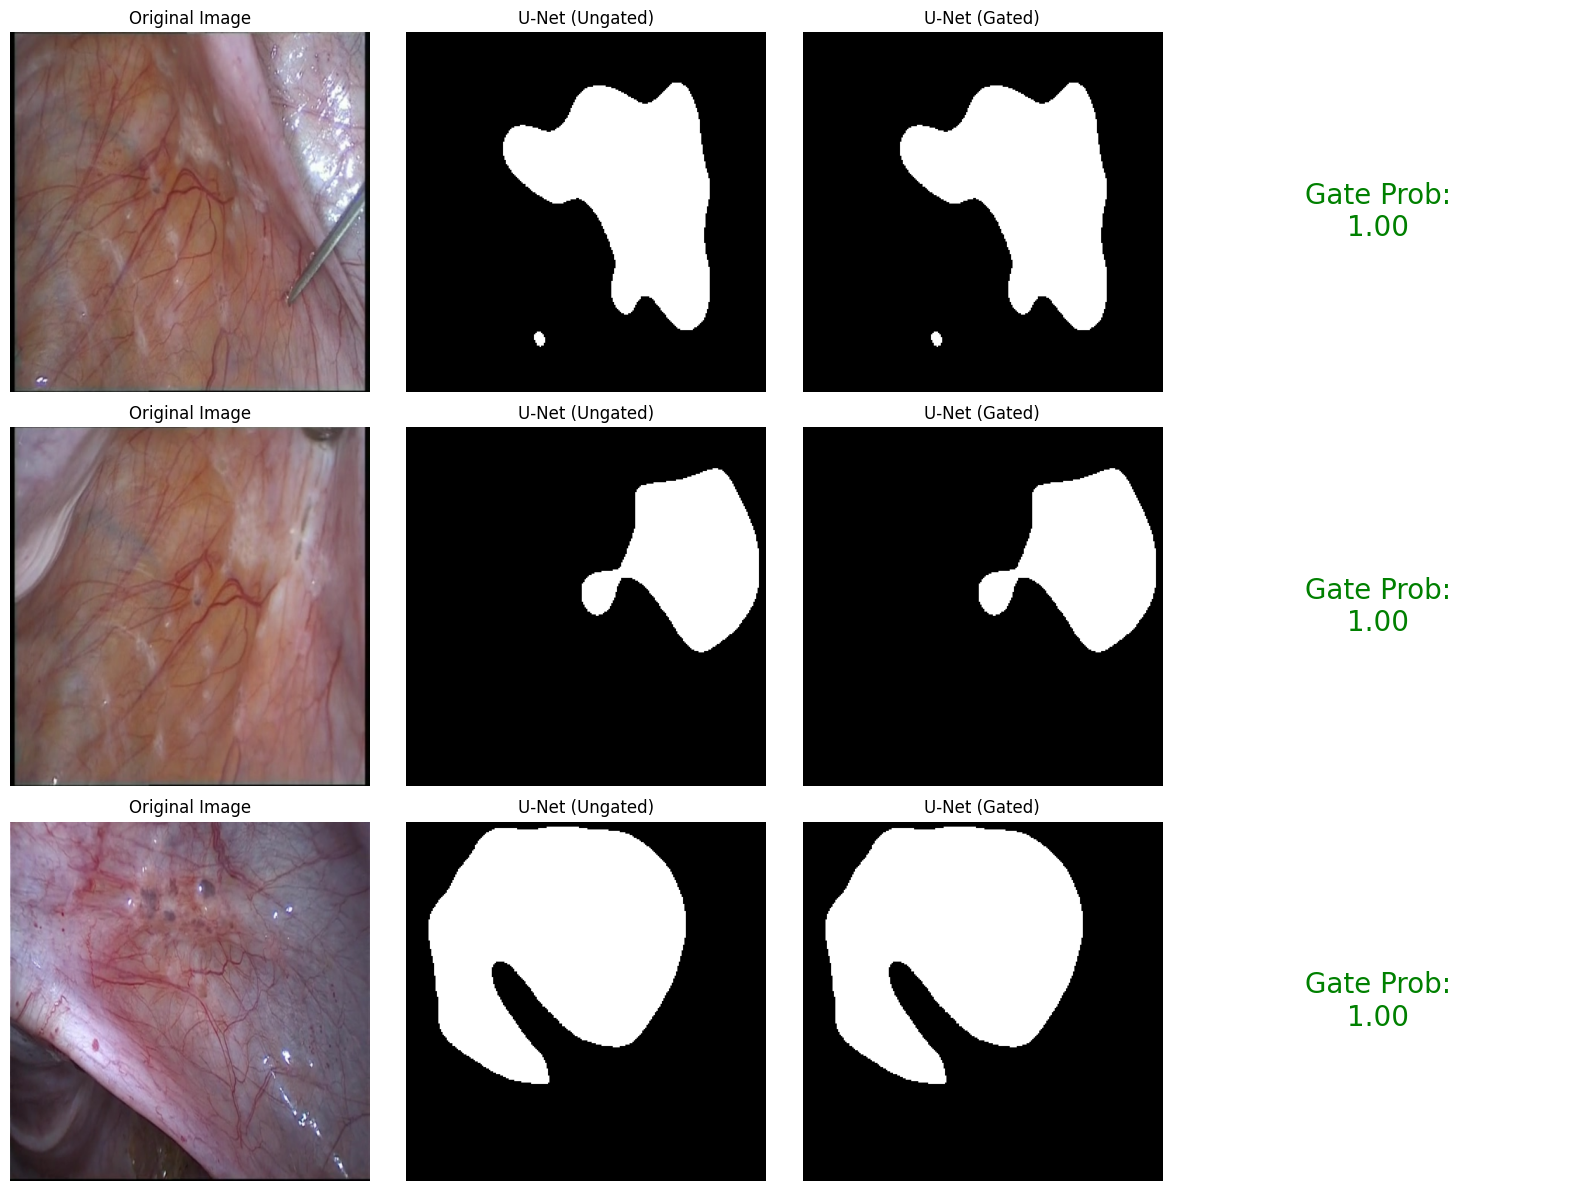

In [ ]:
# rq3 file download
import os
import matplotlib.pyplot as plt

SAVE_DIR = "/content/drive/MyDrive/glenda_dashboard_files/"
os.makedirs(SAVE_DIR, exist_ok=True)

# 6. Visualize the Gate Effect
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for i, data in enumerate(visual_data):
    axes[i, 0].imshow(data["img"]); axes[i, 0].set_title("Original Image"); axes[i, 0].axis("off")
    axes[i, 1].imshow(data["ungated_mask"], cmap="gray"); axes[i, 1].set_title("U-Net (Ungated)"); axes[i, 1].axis("off")
    axes[i, 2].imshow(data["gated_mask"], cmap="gray"); axes[i, 2].set_title("U-Net (Gated)"); axes[i, 2].axis("off")
    axes[i, 3].text(0.5, 0.5, f"Gate Prob:\n{data['gate_prob']:.2f}", ha='center', va='center', fontsize=20, color="green" if data['gate_prob'] > 0.5 else "red")
    axes[i, 3].axis("off")

plt.tight_layout()

# SAVE THE FILE DIRECTLY TO DRIVE HERE:
save_path = os.path.join(SAVE_DIR, "rq3.png")
plt.savefig(save_path, bbox_inches='tight', dpi=300)
print(f"✅ Saved image to: {save_path}")

plt.show()

In [ ]:
# generating missing files
import os
import matplotlib.pyplot as plt
import torch
from pathlib import Path
import numpy as np
from PIL import Image

# Create the save directory
SAVE_DIR = "/content/drive/MyDrive/glenda_dashboard_files/"
os.makedirs(SAVE_DIR, exist_ok=True)

# ==========================================
# 1. GENERATE RQ1 IMAGE (ResNet Predictions)
# ==========================================
print("Generating RQ1 Image...")
# We grab 3 images from the validation set
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i in range(3):
    row = val_df.iloc[i]
    stem = Path(row["file_name"]).stem
    img_path = Path("/content/data/interim/images_512") / f"{stem}.png"
    img_pil = Image.open(img_path).convert("RGB")

    # Predict
    img_tensor = val_transforms(img_pil).unsqueeze(0).to(device)
    with torch.no_grad():
        prob = torch.sigmoid(model_gate_v2(img_tensor)).item()

    true_label = 0 if row["classes"] == "no_pathology" else 1

    axes[i].imshow(img_pil)
    color = "green" if (true_label == 1 and prob > 0.5) or (true_label == 0 and prob <= 0.5) else "red"
    axes[i].set_title(f"True: {true_label} | Pred: {prob:.2f}", color=color)
    axes[i].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "rq1.png"), bbox_inches='tight', dpi=300)
plt.close()
print(f"✅ Saved rq1.png")


# ==========================================
# 2. GENERATE RQ2/RQ5 IMAGE (U-Net vs Tversky)
# ==========================================
print("Generating RQ2/RQ5 Image...")
# Use the positive validation dataframe
pos_val_df = val_df[val_df["classes"] != "no_pathology"].reset_index(drop=True)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for i in range(3):
    row = pos_val_df.iloc[i]
    stem = Path(row["file_name"]).stem

    # Load image and true mask
    img_path = Path("/content/data/interim/images_512") / f"{stem}.png"
    mask_path = Path("/content/data/interim/masks_binary") / f"{stem}.png"

    img_pil = Image.open(img_path).convert("RGB")
    mask_pil = Image.open(mask_path).convert("L")

    # Predict with Baseline U-Net
    img_tensor = img_transform(img_pil).unsqueeze(0).to(device)
    with torch.no_grad():
        pred_base = torch.sigmoid(model_unet_v2(img_tensor))
        pred_base = (pred_base > 0.5).float().cpu().squeeze().numpy()

        pred_tver = torch.sigmoid(model_unet_tversky_v2(img_tensor))
        pred_tver = (pred_tver > 0.5).float().cpu().squeeze().numpy()

    axes[i, 0].imshow(img_pil); axes[i, 0].set_title("Image"); axes[i, 0].axis("off")
    axes[i, 1].imshow(np.array(mask_pil.resize((256,256))), cmap="gray"); axes[i, 1].set_title("True Mask"); axes[i, 1].axis("off")
    axes[i, 2].imshow(pred_base, cmap="gray"); axes[i, 2].set_title("Baseline U-Net"); axes[i, 2].axis("off")
    axes[i, 3].imshow(pred_tver, cmap="gray"); axes[i, 3].set_title("Tversky U-Net"); axes[i, 3].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "rq2_rq5.png"), bbox_inches='tight', dpi=300)
plt.close()
print(f"✅ Saved rq2_rq5.png")

Generating RQ1 Image...
✅ Saved rq1.png
Generating RQ2/RQ5 Image...
✅ Saved rq2_rq5.png
